In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.append(str(Path.cwd().parent / "src"))
from airfoil.data import load_data
from airfoil.features import basic_features
from airfoil.validation import cross_validate_model, make_cv_schemes

df = load_data()
y = df["spl_db"].to_numpy()
schemes = make_cv_schemes(df)   

In [2]:
# Standardise inside the pipeline so scaling is re-fitted on each training fold
# (no information leaks from the test fold). See conditioning notebook.
model = make_pipeline(StandardScaler(), LinearRegression())

rows = []
per_fold = {}
for feat_name, use_log in [("Raw inputs", False), ("Log freq and δ*", True)]:
    X = basic_features(df, log_transform=use_log)
    for scheme, (cv, groups) in schemes.items():
        res = cross_validate_model(model, X, y, cv, groups)
        per_fold[(feat_name, scheme)] = res
        rows.append({
            "Features": feat_name,
            "Scheme": scheme,
            "RMSE mean (dB)": res["rmse"].mean(),
            "RMSE std (dB)": res["rmse"].std(),
            "MAE mean (dB)": res["mae"].mean(),
            "R² mean": res["r2"].mean(),
            "Worst error (dB)": res["max_error"].max(),
        })

summary = pd.DataFrame(rows)
summary.round(2)

,Features,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,Raw inputs,random,4.83,0.28,3.75,0.51,17.63
1,Raw inputs,grouped,4.84,0.41,3.77,0.50,18.13
2,Raw inputs,leave_one_chord_out,4.88,1.61,3.88,0.39,18.98
3,Log freq and δ*,random,5.05,0.24,3.93,0.46,21.72
4,Log freq and δ*,grouped,5.09,0.43,3.94,0.44,22.44
5,Log freq and δ*,leave_one_chord_out,5.10,1.54,4.07,0.33,24.27


In [3]:
# Which chord is hardest to predict when it's never seen in training?
loco = per_fold[("Raw inputs", "leave_one_chord_out")].copy()
loco.insert(1, "Held-out chord (m)", np.sort(df["chord_m"].unique()))
loco.round({"Held-out chord (m)": 4, "rmse": 2, "mae": 2, "r2": 2, "max_error": 2})

,fold,Held-out chord (m),n_test,rmse,mae,r2,max_error
0,0,0.0254,278,7.96,6.25,-0.56,18.98
1,1,0.0508,237,4.24,3.48,0.48,11.34
2,2,0.1016,263,4.85,3.82,0.60,15.43
3,3,0.1524,271,4.71,3.98,0.58,11.55
4,4,0.2286,266,4.31,3.33,0.51,13.43
5,5,0.3048,188,3.21,2.42,0.72,9.20


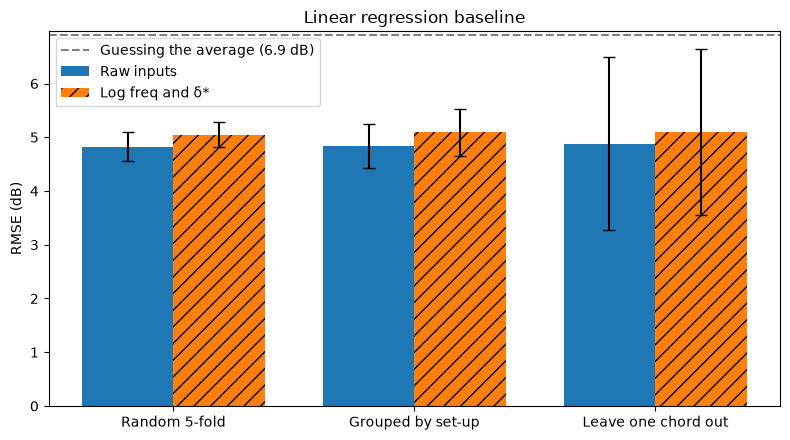

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
scheme_order = ["random", "grouped", "leave_one_chord_out"]
width = 0.38

for i, (feat_name, hatch) in enumerate([("Raw inputs", ""), ("Log freq and δ*", "//")]):
    sub = summary[summary["Features"] == feat_name].set_index("Scheme").loc[scheme_order]
    x = np.arange(len(scheme_order)) + (i - 0.5) * width
    ax.bar(x, sub["RMSE mean (dB)"], width, yerr=sub["RMSE std (dB)"],
           capsize=4, hatch=hatch, label=feat_name)

ax.axhline(6.9, linestyle="--", color="gray", label="Guessing the average (6.9 dB)")
ax.set_xticks(np.arange(len(scheme_order)))
ax.set_xticklabels(["Random 5-fold", "Grouped by set-up", "Leave one chord out"])
ax.set_ylabel("RMSE (dB)")
ax.set_title("Linear regression baseline")
ax.legend()
plt.tight_layout()
plt.savefig("../results/baseline_linear_cv.png", dpi=150)
plt.show()

## Linear regression baseline

**Results (RMSE in dB, mean ± std across folds)**

| Features | Random 5-fold | Grouped by set-up | Leave one chord out |
|:--|:-:|:-:|:-:|
| Raw inputs | 4.83 ± 0.28 | 4.84 ± 0.41 | 4.88 ± 1.61 |
| Log freq and δ* | 5.05 ± 0.24 | 5.09 ± 0.43 | 5.10 ± 1.54 |

**Leave one chord out, raw inputs, fold by fold**

| Held-out chord (m) | 0.0254 | 0.0508 | 0.1016 | 0.1524 | 0.2286 | 0.3048 |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|
| RMSE (dB) | 7.96 | 4.24 | 4.85 | 4.71 | 4.31 | 3.21 |
| R² | −0.56 | 0.48 | 0.60 | 0.58 | 0.51 | 0.72 |

**What I found**
- **Linear regression beats guessing the average, but only modestly:**
  4.84 dB versus 6.9 dB under grouped CV, with R² = 0.50. A straight line
  can't follow the hump-shaped spectra.
- **Random vs grouped barely differ** (4.83 vs 4.84 dB). A model this simple
  can't memorise individual set-ups, so leakage hardly helps it. I expect a
  bigger gap for flexible models like SVR.
- **Unseen chord lengths give very uneven results.** The average (4.88 dB)
  hides a big spread (± 1.61 dB). The smallest chord (0.0254 m) is the
  worst at 7.96 dB, with a negative R², so the model is worse than guessing
  for that blade. The largest chord (0.3048 m) is the best at 3.21 dB.
- **This is the opposite of my Phase 1 prediction.** I expected the largest
  chord to be hardest because it has the fewest rows. A likely reason is
  that 0.0254 m is much further from the other chords (half the size of the
  next one), so predicting it means extrapolating further.
- **The log transform made the linear model slightly worse** (about 0.2 dB
  under every scheme, and larger worst-case errors). A straight line can't
  fit the spectral hump on any scale, so I'll test the transform again for
  each flexible model in Phase 4.

**Note on averaging:** the RMSE values are the mean of the per-fold RMSEs.
Pooling all predictions instead gives 5.22 dB for leave-one-chord-out,
because it weights the large errors on the smallest chord more heavily.

**Takeaway:** the score to beat is **4.84 dB** (raw inputs, grouped
cross-validation).

## Physics scaling-law baseline

In [5]:
from airfoil.physics import ScalingLawModel

X_raw = basic_features(df)   # the physics model needs raw units

for name, model in [("Physics (fixed U⁵)", ScalingLawModel(degree=3)),
                    ("Physics (fitted exponents)", ScalingLawModel(degree=3, fit_exponents=True))]:
    for scheme, (cv, groups) in schemes.items():
        res = cross_validate_model(model, X_raw, y, cv, groups)
        per_fold[(name, scheme)] = res
        rows.append({
            "Features": name,
            "Scheme": scheme,
            "RMSE mean (dB)": res["rmse"].mean(),
            "RMSE std (dB)": res["rmse"].std(),
            "MAE mean (dB)": res["mae"].mean(),
            "R² mean": res["r2"].mean(),
            "Worst error (dB)": res["max_error"].max(),
        })

summary = pd.DataFrame(rows)
summary.round(2)

,Features,Scheme,RMSE mean (dB),RMSE std (dB),MAE mean (dB),R² mean,Worst error (dB)
0,Raw inputs,random,4.83,0.28,3.75,0.51,17.63
1,Raw inputs,grouped,4.84,0.41,3.77,0.50,18.13
2,Raw inputs,leave_one_chord_out,4.88,1.61,3.88,0.39,18.98
3,Log freq and δ*,random,5.05,0.24,3.93,0.46,21.72
4,Log freq and δ*,grouped,5.09,0.43,3.94,0.44,22.44
5,Log freq and δ*,leave_one_chord_out,5.10,1.54,4.07,0.33,24.27
6,Physics (fixed U⁵),random,8.75,0.52,7.08,-0.62,27.51
7,Physics (fixed U⁵),grouped,8.87,0.56,7.21,-0.67,27.72
8,Physics (fixed U⁵),leave_one_chord_out,9.13,1.98,7.50,-1.11,29.02
9,Physics (fitted exponents),random,4.73,0.33,3.58,0.53,23.69


In [6]:
# Fit on all the data to read off the exponents the data prefers
fitted = ScalingLawModel(degree=3, fit_exponents=True).fit(X_raw, y)
print(f"Velocity exponent:  SPL ~ U^{fitted.velocity_exponent_:.2f}   (theory: 5)")
print(f"δ* exponent:        SPL ~ δ*^{fitted.delta_star_exponent_:.2f}  (theory: 1)")

Velocity exponent:  SPL ~ U^0.03   (theory: 5)
δ* exponent:        SPL ~ δ*^-0.29  (theory: 1)


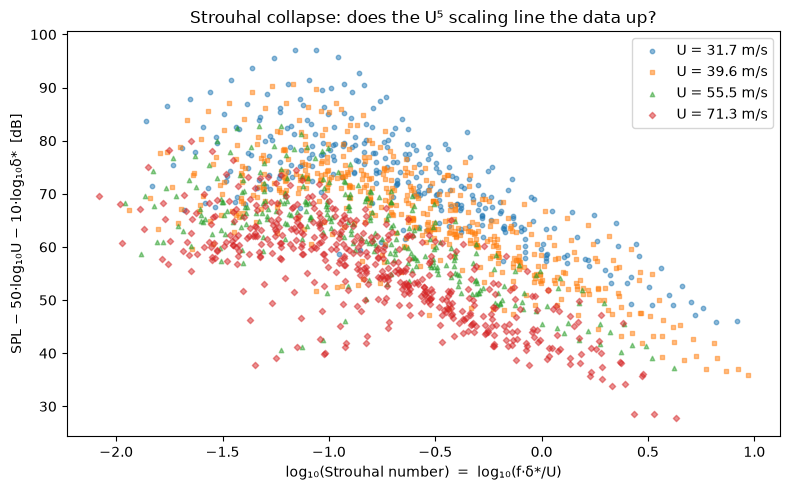

In [7]:
log_st = np.log10(df["frequency_hz"] * df["delta_star_m"] / df["velocity_ms"])
scaled_spl = y - 50 * np.log10(df["velocity_ms"]) - 10 * np.log10(df["delta_star_m"])

fig, ax = plt.subplots(figsize=(8, 5))
markers = {31.7: "o", 39.6: "s", 55.5: "^", 71.3: "D"}
for vel, marker in markers.items():
    mask = df["velocity_ms"] == vel
    ax.scatter(log_st[mask], scaled_spl[mask], s=10, alpha=0.5,
               marker=marker, label=f"U = {vel} m/s")

ax.set_xlabel("log₁₀(Strouhal number)  =  log₁₀(f·δ*/U)")
ax.set_ylabel("SPL − 50·log₁₀U − 10·log₁₀δ*  [dB]")
ax.set_title("Strouhal collapse: does the U⁵ scaling line the data up?")
ax.legend()
plt.tight_layout()
plt.savefig("../results/strouhal_collapse.png", dpi=150)
plt.show()

In [8]:
loco_phys = per_fold[("Physics (fitted exponents)", "leave_one_chord_out")].copy()
loco_phys.insert(1, "Held-out chord (m)", np.sort(df["chord_m"].unique()))
loco_phys.round({"Held-out chord (m)": 4, "rmse": 2, "mae": 2, "r2": 2, "max_error": 2})

,fold,Held-out chord (m),n_test,rmse,mae,r2,max_error
0,0,0.0254,278,8.55,6.20,-0.80,28.11
1,1,0.0508,237,5.16,4.33,0.23,15.65
2,2,0.1016,263,4.59,3.73,0.65,15.43
3,3,0.1524,271,3.47,2.76,0.77,10.88
4,4,0.2286,266,3.65,2.88,0.65,11.35
5,5,0.3048,188,4.62,3.75,0.43,12.77


## Physics scaling-law baseline

**Results (RMSE in dB, mean ± std across folds)**

| Model | Fitted numbers | Random 5-fold | Grouped by set-up | Leave one chord out |
|:--|:-:|:-:|:-:|:-:|
| Linear regression (raw) | 6 | 4.83 ± 0.28 | 4.84 ± 0.41 | 4.88 ± 1.61 |
| Physics (fixed U⁵) | 5 | 8.75 ± 0.52 | 8.87 ± 0.56 | 9.13 ± 1.98 |
| Physics (fitted exponents) | 7 | 4.73 ± 0.33 | 4.80 ± 0.55 | 5.01 ± 1.85 |

Fitted exponents (all data): SPL ~ U^0.03 (theory 5), SPL ~ δ*^−0.29 (theory 1).

**What I found**
- **Textbook physics fails on this data.** Forcing U⁵ scaling gives 8.87 dB
  and a negative R², worse than just guessing the average (6.9 dB).
- **With fitted exponents, physics ties with linear regression** (4.80 vs
  4.84 dB under grouped CV, well within the fold-to-fold spread). Two very
  different simple models reach the same ~4.8 dB level, which suggests
  that's roughly the limit for simple models here. Physics does slightly
  worse on unseen chords (5.01 vs 4.88 dB) and has larger worst-case errors.
- **The data's speed exponent is about 0, not 5.** At a fixed Strouhal
  number, the noise level barely changes with speed, which matches my
  Phase 1 observation that the spectra peaks were almost equally loud at
  every speed.
- **The Strouhal collapse plot shows separate bands for each speed**, about
  15–20 dB apart. That's close to the 17.6 dB I subtracted with the U⁵
  term, so the subtraction created the separation instead of removing it.
  The bands peak around log₁₀ St ≈ −1.2 (St ≈ 0.06), matching my earlier
  hand calculation.
- **Why?** Possibly NASA's undocumented "scaled" SPL already removes much of
  the speed dependence. The exact exponents should also be treated with
  caution: δ* is calculated from speed, chord and angle, so the fit can
  trade the exponents off against each other. The negative δ* exponent is
  a sign of this, since physically a thicker boundary layer should be
  louder.
- **Unseen chords:** the hardest is still the 0.0254 m chord (8.55 dB, worse
  than linear's 7.96 dB). Physics does better than linear on the middle
  chords (e.g. 3.47 vs 4.71 dB at 0.1524 m) but worse at both ends of the
  range.

**Takeaway:** simple physics, once its exponents are fitted, does as well as
linear regression with an interpretable model, but textbook U⁵ scaling does
not hold for this scaled dataset. Both baselines reach about 4.8 dB, so the
ML models need to beat that clearly to justify their complexity.

## Baseline comparison

In [9]:
# Rename columns and labels so the table reads clearly
comparison = summary.rename(columns={"Features": "Model"}).copy()
comparison["Model"] = comparison["Model"].replace({
    "Raw inputs": "Linear (raw)",
    "Log freq and δ*": "Linear (log f, δ*)",
})

# Save for Phase 5, so ML models can be compared with the baselines
comparison.to_csv("../results/baseline_results.csv", index=False)

# Format as "mean ± std" and lay out models x schemes
comparison["RMSE (dB)"] = (comparison["RMSE mean (dB)"].map("{:.2f}".format)
                           + " ± " + comparison["RMSE std (dB)"].map("{:.2f}".format))
order = ["Linear (raw)", "Linear (log f, δ*)", "Physics (fixed U⁵)", "Physics (fitted exponents)"]
schemes_order = ["random", "grouped", "leave_one_chord_out"]
table = comparison.pivot(index="Model", columns="Scheme", values="RMSE (dB)")
table.loc[order, schemes_order]

Scheme,random,grouped,leave_one_chord_out
Model,,,
Linear (raw),4.83 ± 0.28,4.84 ± 0.41,4.88 ± 1.61
"Linear (log f, δ*)",5.05 ± 0.24,5.09 ± 0.43,5.10 ± 1.54
Physics (fixed U⁵),8.75 ± 0.52,8.87 ± 0.56,9.13 ± 1.98
Physics (fitted exponents),4.73 ± 0.33,4.80 ± 0.55,5.01 ± 1.85


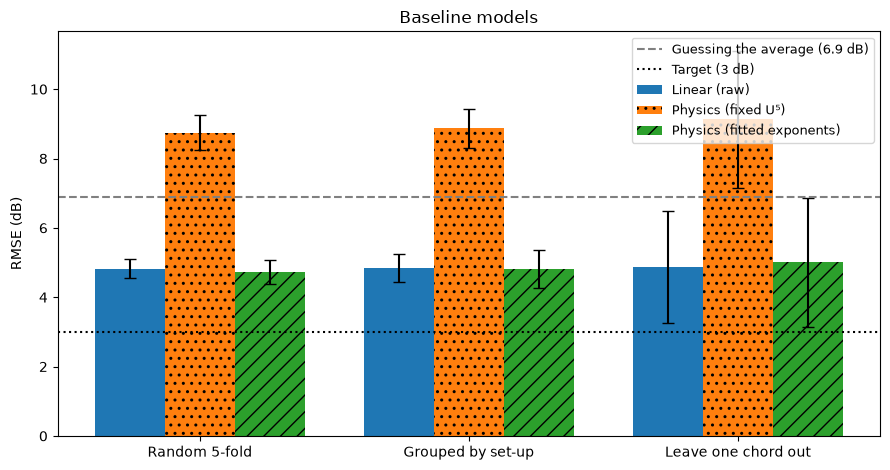

In [10]:
models_to_plot = [("Linear (raw)", ""),
                  ("Physics (fixed U⁵)", ".."),
                  ("Physics (fitted exponents)", "//")]
width = 0.26
fig, ax = plt.subplots(figsize=(9, 4.8))

for i, (model_name, hatch) in enumerate(models_to_plot):
    sub = comparison[comparison["Model"] == model_name].set_index("Scheme").loc[schemes_order]
    x = np.arange(len(schemes_order)) + (i - 1) * width
    ax.bar(x, sub["RMSE mean (dB)"], width, yerr=sub["RMSE std (dB)"],
           capsize=4, hatch=hatch, label=model_name)

ax.axhline(6.9, linestyle="--", color="gray", label="Guessing the average (6.9 dB)")
ax.axhline(3.0, linestyle=":", color="black", label="Target (3 dB)")
ax.set_xticks(np.arange(len(schemes_order)))
ax.set_xticklabels(["Random 5-fold", "Grouped by set-up", "Leave one chord out"])
ax.set_ylabel("RMSE (dB)")
ax.set_title("Baseline models")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../results/baseline_comparison.png", dpi=150)
plt.show()

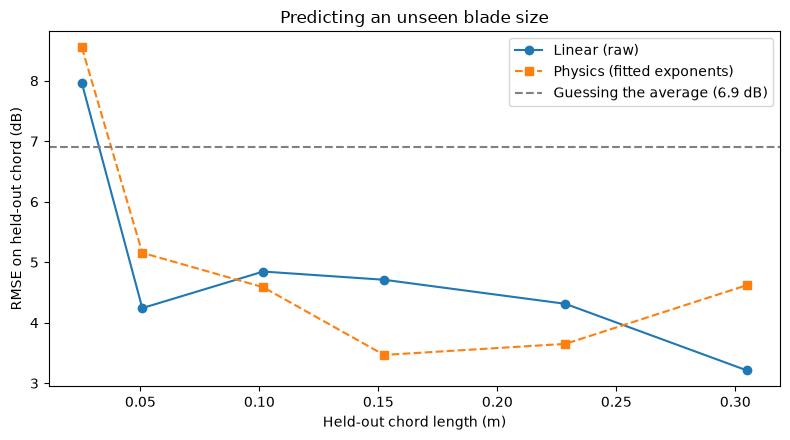

,Held-out chord (m),Linear (raw),Physics (fitted exponents)
0,0.0254,7.96,8.55
1,0.0508,4.24,5.16
2,0.1016,4.85,4.59
3,0.1524,4.71,3.47
4,0.2286,4.31,3.65
5,0.3048,3.21,4.62


In [11]:
chords = np.sort(df["chord_m"].unique())
per_chord = pd.DataFrame({
    "Held-out chord (m)": chords,
    "Linear (raw)": per_fold[("Raw inputs", "leave_one_chord_out")]["rmse"].to_numpy(),
    "Physics (fitted exponents)": per_fold[("Physics (fitted exponents)", "leave_one_chord_out")]["rmse"].to_numpy(),
})

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(per_chord["Held-out chord (m)"], per_chord["Linear (raw)"],
        marker="o", label="Linear (raw)")
ax.plot(per_chord["Held-out chord (m)"], per_chord["Physics (fitted exponents)"],
        marker="s", linestyle="--", label="Physics (fitted exponents)")
ax.axhline(6.9, linestyle="--", color="gray", label="Guessing the average (6.9 dB)")
ax.set_xlabel("Held-out chord length (m)")
ax.set_ylabel("RMSE on held-out chord (dB)")
ax.set_title("Predicting an unseen blade size")
ax.legend()
plt.tight_layout()
plt.savefig("../results/baseline_per_chord.png", dpi=150)
plt.show()

per_chord.round({"Held-out chord (m)": 4, "Linear (raw)": 2, "Physics (fitted exponents)": 2})

### What the comparison shows
- **Both usable baselines sit at about 4.8 dB** under grouped CV (linear
  4.84, physics with fitted exponents 4.80). Neither comes close to my 3 dB
  target, so there's clear room for the ML models to improve.
- **Textbook physics (fixed U⁵) is the only model worse than guessing the
  average** (8.87 dB), because this data doesn't follow U⁵ scaling.
- **Unseen blade sizes:** for the smallest chord (0.0254 m), linear gives
  7.96 dB and physics 8.55 dB, so both models fail there (worse than
  guessing the average). Physics is better for the middle chords, where
  predicting means interpolating between tested sizes (e.g. 3.47 vs 4.71 dB
  at 0.1524 m). Linear is better at both ends, where predicting means
  extrapolating: a curved model can bend off in the wrong direction outside
  the data, while a straight line stays more conservative.
- In the per-chord plot the physics error is U-shaped and the two lines
  cross twice, so neither baseline is better everywhere.

### Phase 3 summary
- **Score to beat: about 4.8 dB** (grouped cross-validation).
- Random and grouped CV give almost the same result for these simple
  models, so leakage barely helps them. I'll check whether this changes
  for the flexible ML models.
- The data's velocity exponent is about 0, not the textbook 5, at fixed
  Strouhal number.
- Predicting unseen blade sizes is the hardest task, especially the
  smallest chord, where both baselines fail.
- Interpolating between tested blade sizes is much easier than
  extrapolating beyond them. This is the global vs local fitting
  trade-off.